## Propozycje ulepszenia danych wejściowych do treningu

### Saliency map

Wczytuję: ..\data\saliency_data\city_night_rain_1510_1_m8zLv8SA.jpg


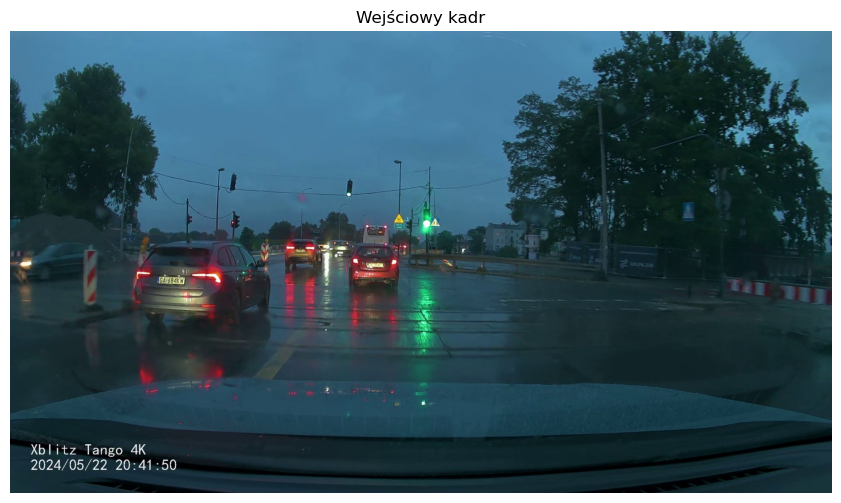

In [68]:
import os
from pathlib import Path
import numpy as np
import cv2
import matplotlib.pyplot as plt

# obraz
# IMG_PATH = Path("../data/saliency_data/city_daylight_2_1_c7VEobYA.jpg")
IMG_PATH = Path("../data/saliency_data/city_night_rain_1510_1_m8zLv8SA.jpg")

# Katalog wyjściowy
# OUT_DIR = Path("saliency_outputs_daylight")
OUT_DIR = Path("saliency_outputs_night_rain")
OUT_DIR.mkdir(parents=True, exist_ok=True)

assert IMG_PATH.exists(), f"Nie znaleziono pliku: {IMG_PATH}"
print("Wczytuję:", IMG_PATH)

# OpenCV czyta w BGR
img_bgr = cv2.imread(str(IMG_PATH), cv2.IMREAD_COLOR)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 6))
plt.imshow(img_rgb)
plt.title("Wejściowy kadr")
plt.axis("off")
plt.show()

In [69]:
def norm01(x: np.ndarray) -> np.ndarray:
    x = x.astype(np.float32)
    mn, mx = x.min(), x.max()
    if mx - mn < 1e-12:
        return np.zeros_like(x, dtype=np.float32)
    return (x - mn) / (mx - mn)


def to_uint8(x01: np.ndarray) -> np.ndarray:
    return (np.clip(x01, 0, 1) * 255).astype(np.uint8)


def show_gray(img01, title=""):
    plt.figure(figsize=(10, 5))
    plt.imshow(img01, cmap="gray")
    plt.title(title)
    plt.axis("off")
    plt.show()

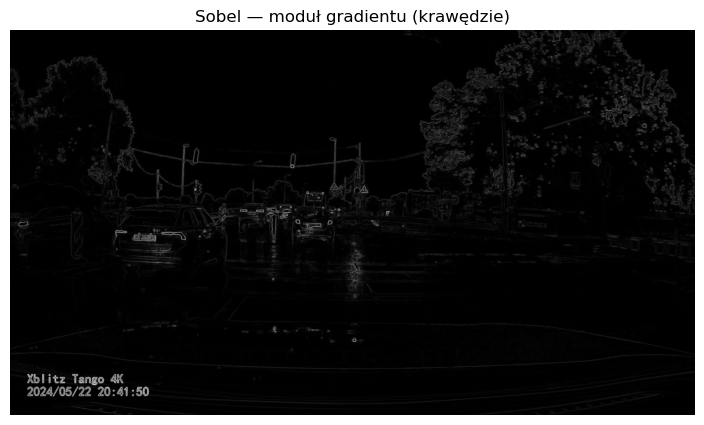

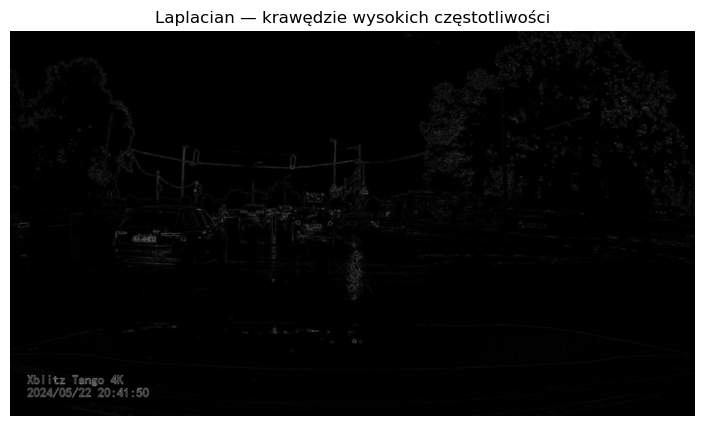

In [70]:
gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

# SOBEL (moduł gradientu)
gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
sobel_mag = np.sqrt(gx**2 + gy**2)
sobel01 = norm01(sobel_mag)

# LAPLACIAN (wysokie częstotliwości)
lap = cv2.Laplacian(gray, cv2.CV_32F, ksize=3)
lap01 = norm01(np.abs(lap))

show_gray(sobel01, "Sobel — moduł gradientu (krawędzie)")
show_gray(lap01, "Laplacian — krawędzie wysokich częstotliwości")

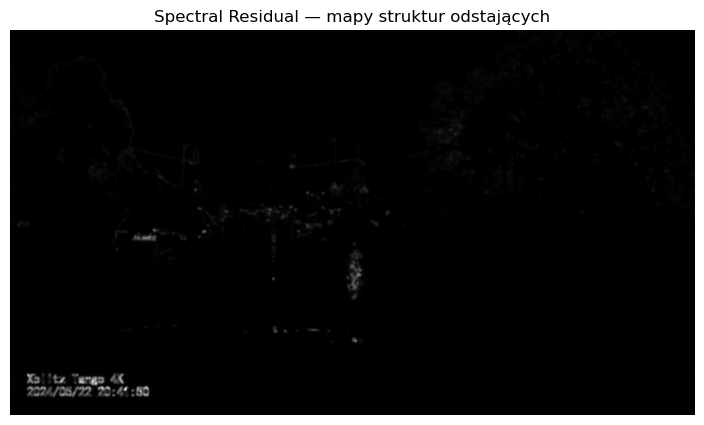

In [71]:
def spectral_residual_saliency(
    gray_img: np.ndarray, blur_ksize=9, blur_sigma=2.5
) -> np.ndarray:
    # 1) FFT
    img = gray_img.astype(np.float32)
    fft = np.fft.fft2(img)
    amp, phase = np.abs(fft), np.angle(fft)

    # 2) log-amplitude i filtr uśredniający
    log_amp = np.log(amp + 1e-8)
    avg_log_amp = cv2.blur(log_amp, (3, 3))

    # 3) residuum widmowe
    res = log_amp - avg_log_amp

    # 4) powrót do dziedziny obrazu
    amp_ = np.exp(res)
    fft_ = amp_ * np.exp(1j * phase)
    sal = np.fft.ifft2(fft_)
    sal = np.abs(sal) ** 2

    # 5) wygładzenie i normalizacja
    sal = cv2.GaussianBlur(sal, (blur_ksize, blur_ksize), blur_sigma)
    return norm01(sal)


sr01 = spectral_residual_saliency(gray)
show_gray(sr01, "Spectral Residual — mapy struktur odstających")

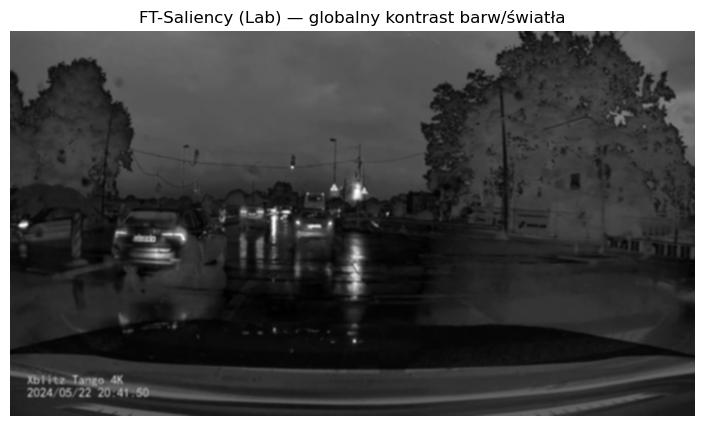

In [72]:
def ft_saliency_lab(img_bgr: np.ndarray) -> np.ndarray:
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB).astype(np.float32)
    mean_lab = lab.reshape(-1, 3).mean(axis=0, keepdims=True)  # globalny średni kolor
    diff = lab.reshape(-1, 3) - mean_lab
    dist = np.sqrt((diff**2).sum(axis=1)).reshape(lab.shape[:2])
    dist = cv2.GaussianBlur(dist, (9, 9), 3.0)
    return norm01(dist)


ft01 = ft_saliency_lab(img_bgr)
show_gray(ft01, "FT-Saliency (Lab) — globalny kontrast barw/światła")

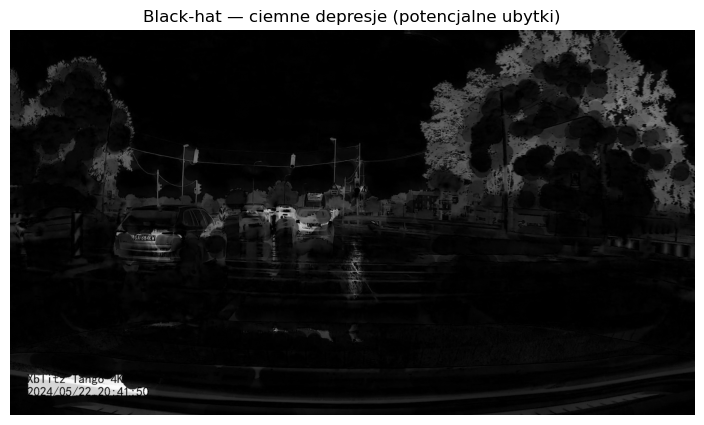

In [73]:
# Duże jądro, by podkreślić „plamy/ubytki” na asfalcie (dopasuj do rozdzielczości)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (41, 41))
blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)
blackhat01 = norm01(blackhat)

show_gray(blackhat01, "Black-hat — ciemne depresje (potencjalne ubytki)")

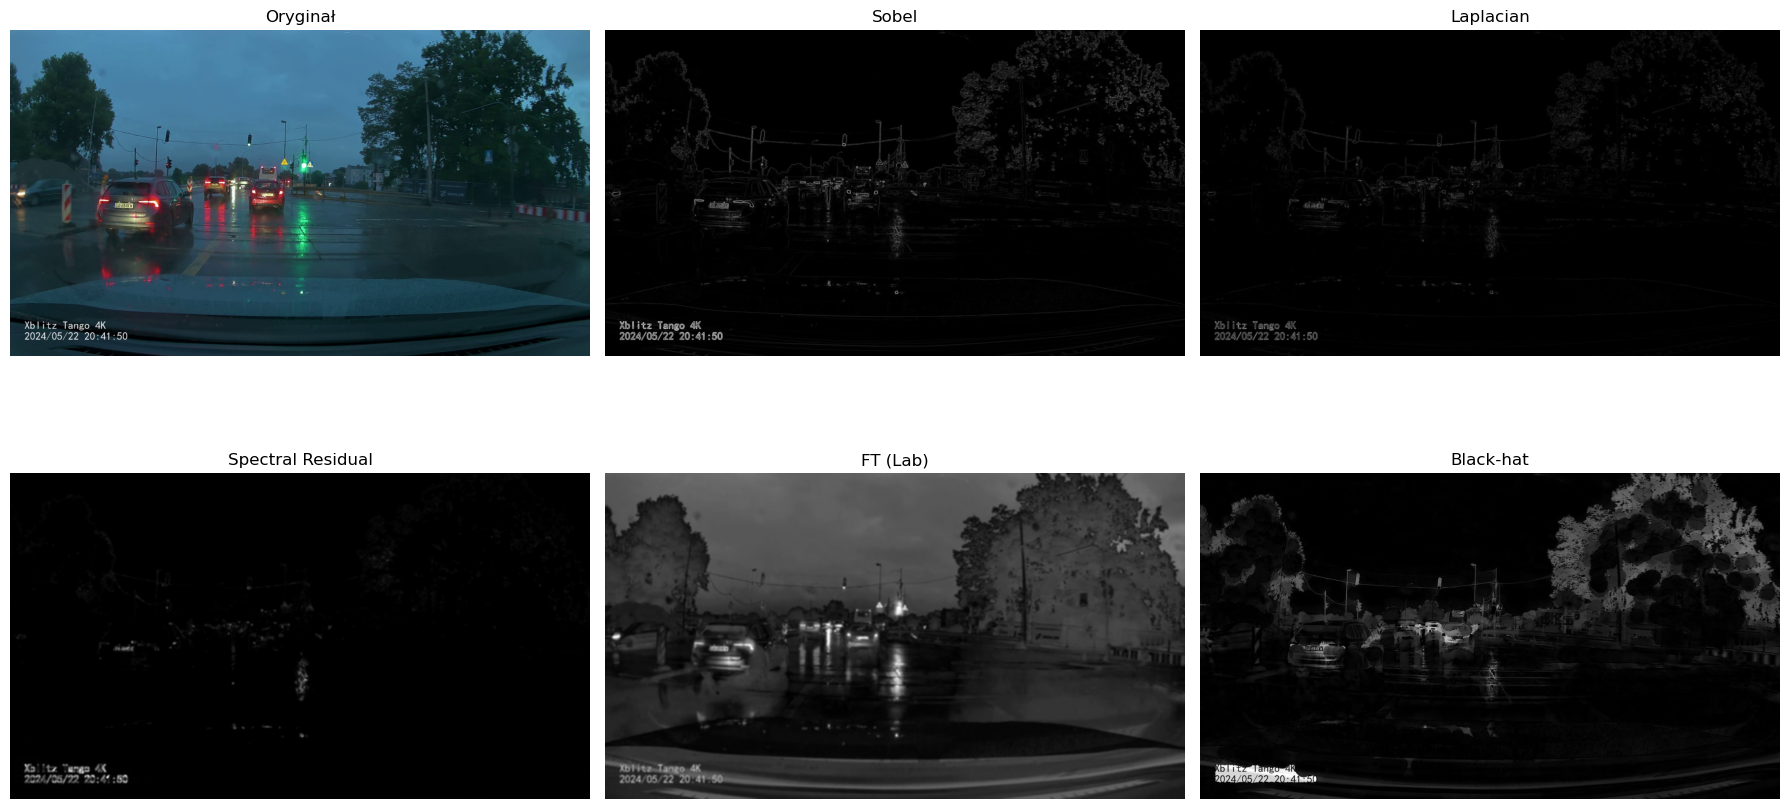

In [74]:
fig, axs = plt.subplots(2, 3, figsize=(18, 10))
axs = axs.ravel()

axs[0].imshow(img_rgb)
axs[0].set_title("Oryginał")
axs[0].axis("off")
axs[1].imshow(sobel01, cmap="gray")
axs[1].set_title("Sobel")
axs[1].axis("off")
axs[2].imshow(lap01, cmap="gray")
axs[2].set_title("Laplacian")
axs[2].axis("off")
axs[3].imshow(sr01, cmap="gray")
axs[3].set_title("Spectral Residual")
axs[3].axis("off")
axs[4].imshow(ft01, cmap="gray")
axs[4].set_title("FT (Lab)")
axs[4].axis("off")
axs[5].imshow(blackhat01, cmap="gray")
axs[5].set_title("Black-hat")
axs[5].axis("off")

plt.tight_layout()
plt.show()

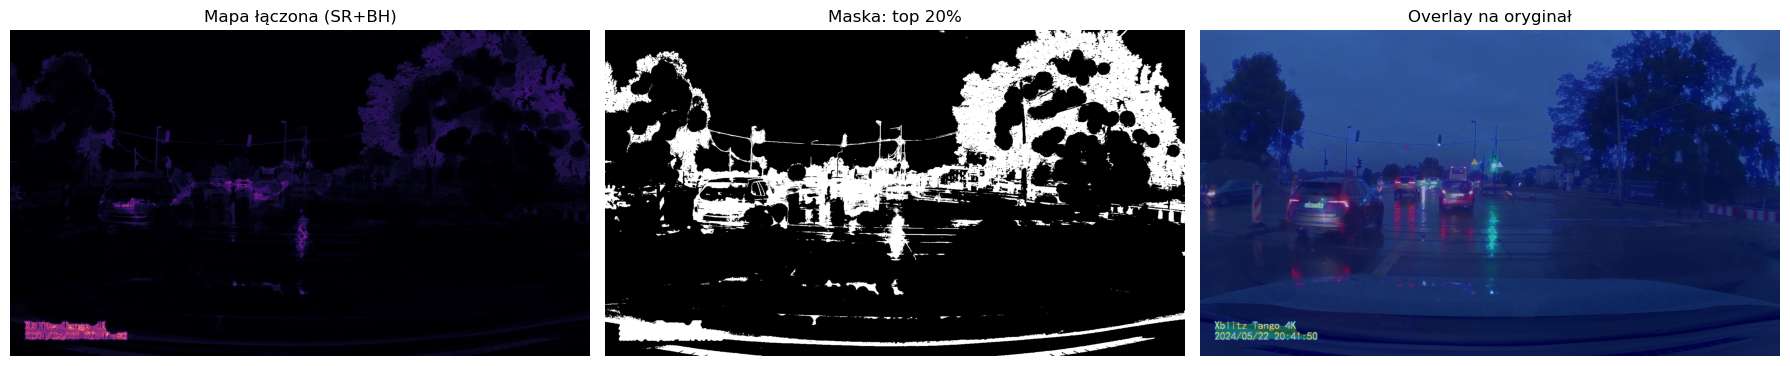

Zapisano do: C:\Users\adamp\OneDrive\Pulpit\MGR\Master\CarVision_MGR\notebooks\saliency_outputs_night_rain


In [75]:
# Prosta fuzja: 0.6*SR + 0.4*Black-hat (eksperymentuj!)
combo01 = norm01(0.6 * sr01 + 0.4 * blackhat01)

# Prog: TOP 20% (zmień np. na 10–30%)
p = 80  # percentyl
thr = np.percentile(combo01, p)
mask = (combo01 >= thr).astype(np.uint8)  # 0/1
mask_u8 = (mask * 255).astype(np.uint8)

# Koloryzacja + overlay
heat = cv2.applyColorMap(to_uint8(combo01), cv2.COLORMAP_JET)
overlay_bgr = cv2.addWeighted(img_bgr, 0.65, heat, 0.35, 0)
overlay_rgb = cv2.cvtColor(overlay_bgr, cv2.COLOR_BGR2RGB)

# Zapis
cv2.imwrite(str(OUT_DIR / "saliency_combo.png"), to_uint8(combo01))
cv2.imwrite(str(OUT_DIR / "saliency_mask_top20.png"), mask_u8)
cv2.imwrite(str(OUT_DIR / "saliency_overlay.png"), overlay_bgr)

# Podgląd
plt.figure(figsize=(18, 6))
plt.subplot(1, 3, 1)
plt.imshow(combo01, cmap="magma")
plt.title("Mapa łączona (SR+BH)")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(mask_u8, cmap="gray")
plt.title("Maska: top 20%")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(overlay_rgb)
plt.title("Overlay na oryginał")
plt.axis("off")
plt.tight_layout()
plt.show()

print("Zapisano do:", OUT_DIR.resolve())

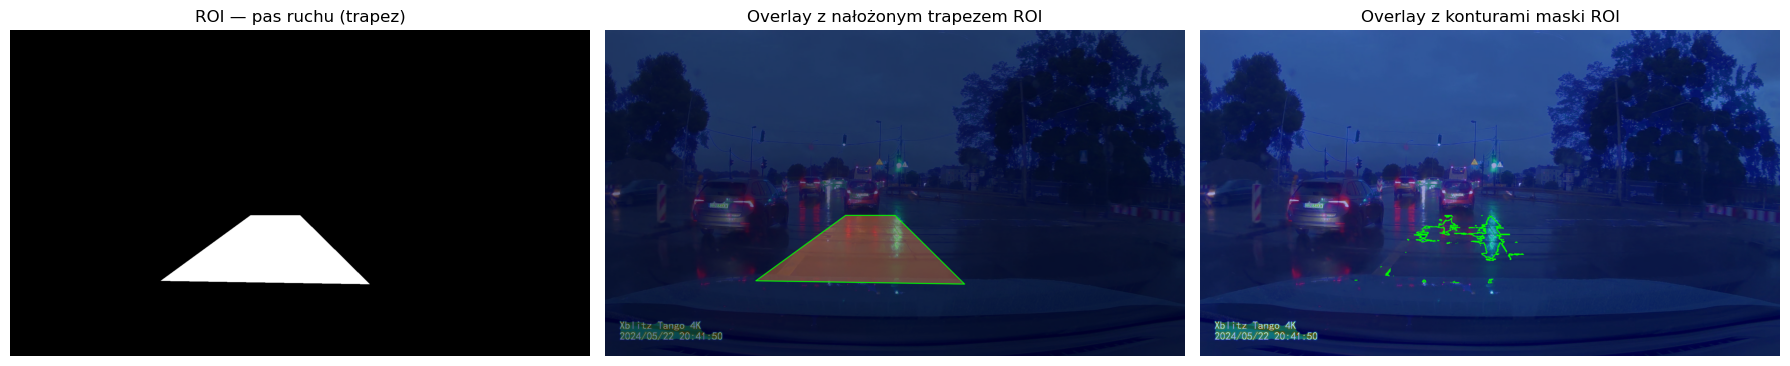

Zapisano:
  saliency_outputs_night_rain\saliency_mask_top20_roi.png 
  saliency_outputs_night_rain\saliency_overlay_roi.png 
  saliency_outputs_night_rain\saliency_overlay_roi_poly.png


In [76]:
h, w = gray.shape[:2]

# Punkty trapezu (x, y) – przykład (dostosuj!)
roi_poly = np.array(
    [
        [
            (int(0.26 * w), int(0.77 * h)),
            (int(0.415 * w), int(0.57 * h)),
            (int(0.5 * w), int(0.57 * h)),
            (int(0.62 * w), int(0.78 * h)),
        ]
    ],
    dtype=np.int32,
)

roi_mask = np.zeros((h, w), dtype=np.uint8)
cv2.fillPoly(roi_mask, roi_poly, 255)

mask_roi = cv2.bitwise_and(mask_u8, roi_mask)

# 1) Overlay z konturami maski (jak poprzednio)
overlay_roi = overlay_bgr.copy()
contours, _ = cv2.findContours(mask_roi, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cv2.drawContours(overlay_roi, contours, -1, (0, 255, 0), 2)

# 2) NOWE: Overlay z półprzezroczystym trapezem na obrazie
roi_overlay_poly_bgr = overlay_bgr.copy()
fill_color = (0, 120, 255)  # BGR (niebiesko-pomarańczowy)
alpha = 0.35

# Warstwa z wypełnionym trapezem
fill_layer = np.zeros_like(roi_overlay_poly_bgr, dtype=np.uint8)
cv2.fillPoly(fill_layer, roi_poly, fill_color)

# Zblenduj z overlay_bgr
roi_overlay_poly_bgr = cv2.addWeighted(
    roi_overlay_poly_bgr, 1 - alpha, fill_layer, alpha, 0
)
# Dorysuj krawędzie trapezu (zielone)
cv2.polylines(
    roi_overlay_poly_bgr, roi_poly, True, (0, 255, 0), 2, lineType=cv2.LINE_AA
)

# 3) Podgląd 3 obrazków
plt.figure(figsize=(18, 6))
plt.subplot(1, 3, 1)
plt.imshow(roi_mask, cmap="gray")
plt.title("ROI — pas ruchu (trapez)")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(overlay_roi, cv2.COLOR_BGR2RGB))
plt.title("Overlay z konturami maski ROI")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(roi_overlay_poly_bgr, cv2.COLOR_BGR2RGB))
plt.title("Overlay z nałożonym trapezem ROI")
plt.axis("off")
plt.tight_layout()
plt.show()

# 4) Zapisy plików
cv2.imwrite(str(OUT_DIR / "saliency_mask_top20_roi.png"), mask_roi)
cv2.imwrite(str(OUT_DIR / "saliency_overlay_roi.png"), overlay_roi)
cv2.imwrite(str(OUT_DIR / "saliency_overlay_roi_poly.png"), roi_overlay_poly_bgr)
print(
    "Zapisano:\n ",
    OUT_DIR / "saliency_mask_top20_roi.png",
    "\n ",
    OUT_DIR / "saliency_overlay_roi.png",
    "\n ",
    OUT_DIR / "saliency_overlay_roi_poly.png",
)

### Wnioski

#### Wnioski z porównania: dzień (clear) vs noc + deszcz
Co dobrze działa w dzień

- Kontrast i tekstura: mapa saliency silnie „łapie” ostre krawędzie ubytków (przejścia jasność/cień) oraz poszarpaną teksturę asfaltu wokół krawędzi dziury.
- Mało fałszywych odpowiedzi: poza liniami pasa i kilkoma artefaktami (np. krawężniki, spoiny), maska skupia się głównie w pasie ruchu.
- ROI (trapez): nałożony trapez dobrze „wycina” dolną część kadru – praktycznie cała użyteczna odpowiedź saliency mieści się w ROI, więc to dobry filtr przestrzenny.

Co dzieje się w nocy + deszczu

- Refleksy i połyski (światła aut, sygnalizacja, odbicia na mokrej nawierzchni) generują bardzo silne odpowiedzi w saliency – to główne źródło FP.
- Szum/rozmycie: niższy SNR i ewentualny motion blur podbijają odpowiedź na granicach świateł i mokrych smug.
- ROI nadal pomaga, ale to za mało: w masce wciąż jest sporo „śmieci” (poza rzeczywistymi ubytkami), zwłaszcza na linii odbić i mokrych pasach.


#### Jak to przełożyć na przygotowanie danych i trening YOLO
Filtrowanie kadrów/obszarów (jakość wejścia)

- Heurystyka jakości kadru: licz odsetek pikseli z wysoką odpowiedzią saliency poza ROI. Jeżeli > X% → odrzuć kadr z treningu lub przenieś do walidacji (by nie uczyć się na skrajnie „błyszczących” obrazach).
- Maskowanie tła przy etykietowaniu: możesz przyciąć etykiety do ROI (nie zmieniasz BB, ale ignorujesz piksele/obszary poza ROI przy augmentacjach typu mosaic/cutout). To obniża ryzyko, że model uczy się „świateł” czy pobocza zamiast dziur.

Wagi próbek/strat sterowane saliency (lekka modyfikacja procesu)

- Ważenie obrazów: obrazy, w których saliency silnie aktywuje się w obrębie ROI (dużo „struktury” bez refleksów) otrzymują większą wagę w samplingu.
- Ważenie boxów: jeżeli masz możliwość, podczas trenowania podbij wagę obiektów (dziur), dla których średnia wartość saliency wewnątrz BB jest wyższa (bardziej „krawędziowe”/teksturalne). To wzmacnia sygnał „co jest istotne”.

Pre-processing zależny od warunków

* Dzień: obecny pipeline (Sobel, Laplacian, Spectral Residual, Black-hat) + ROI jest wystarczający.
* Noc + deszcz: dodaj „specular highlight suppression” (HSV: V↑ & S↓) przed liczeniem saliency; następnie jak dotąd (SR + Black-hat + ROI).
    - Suppresssion = krok wstępny, który osłabia lub wygładza te odbicia, zanim policzysz saliency:
    - najczęściej działa się w HSV: refleksy mają wysokie V (jasność) i niskie S (nasycenie),
    - maskę punktów spełniających warunek przetwarzasz lokalnym wygładzaniem / inpaintingiem, by „zlać” bliki z otoczeniem,
    - dopiero potem następuje Sobel/Laplacian/SR/Black-hat i ROI.

#### Niepewność w detekcji dziur: aleatoryczna i epistemiczna – co to jest i co z tym zrobić

W detekcji z dashcamu mamy dwa główne źródła niepewności przewidywań. Dobrze je rozumieć, bo każda wymaga innej strategii.

1) Niepewność aleatoryczna (losowa, „w danych”)

Wbudowana zmienność sceny i pomiaru. W badanych nagraniach to m.in.: deszcz i mokra nawierzchnia, lustrzane odbicia świateł (refleksy), noc (niski SNR), szum sensora, motion-blur, mgła. Te zjawiska sprawiają, że nawet idealny model czasem się pomyli, bo informacja w obrazie jest dwuznaczna.

Czego się spodziewać?
W nocy i deszczu mapy saliency silnie „łapią” refleksy, a dziury potrafią zlewać się z tłem – rosną FP i/lub FN. Tego nie da się całkowicie usunąć.

Jak ograniczać wpływ (praktyka z Twojego pipeline):

* ROI (trapez) — przycięcie obrazu do pasa ruchu i ignorowanie zbędnych części kadru.
* Specular highlight suppression — przed obliczeniem saliency należy stłumić bardzo jasne piksele (np. w HSV: V wysokie & S niskie → lokalne wygładzenie). To wyraźnie zmniejsza fałszywe aktywacje od odbić.
* Selekcja kadrów — odrzucenie lub niższa waga ujęć, w których saliency poza ROI stanowi zbyt duży odsetek pikseli (sygnał, że kadr jest „za błyszczący/za trudny”).
* Ostrożniejsze progi na inferencji:
    - wyższy confidence threshold w cięższych warunkach (mniej FP),
    - dopasowany próg NMS (IoU), który agresywniej usuwa nakładające się, „refleksowe” boksy (np. niższy IoU w nocy/deszczu). NMS (Non-Maximum Suppression) to krok po detekcji: jeżeli dwa boksy mocno się nakładają, zostaje ten pewniejszy. Próg IoU steruje „jak mocno” muszą się nakładać, by słabszy został skasowany.

2) Niepewność epistemiczna (niewiedza modelu)

Błędy wynikające z braku wiedzy modelu o danej domenie, bo miał za mało podobnych przykładów w treningu. Przykład: rzadkie, nocne sceny w ulewie z silnymi refleksami.

Tę niepewność można redukować:

* Uzupełnianie danych o brakujące domeny (więcej ujęć nocnych i w deszczu, różne kamery, pory roku).
* Augmentacje specyficzne dla problemu: glare/raindrops/motion-blur; scenariusz curriculum (najpierw łatwe dzienne, później trudne nocne).
* Diagnoza w inferencji: TTA (test-time augmentation), ensembling, MC-Dropout. Wysoka wariancja wyników między próbami = wysoka niepewność epistemiczna → wtedy:
    - należy podnieść progi (mniej agresywna detekcja),
    - zweryfikować ręcznie lub wykorzystać drugie źródło (np. czujnik wstrząsów),
    - logować takie przypadki do „kolejki” doszkoleń.

Co z tego wynika dla badanego zagadnienia:

* Dzień (clear): obecny zestaw (Sobel/Laplacian + Spectral Residual + Black-hat) + ROI działa dobrze — saliency wyraźnie podkreśla krawędzie ubytków, niskie FP.
* Noc + deszcz: bez tłumienia bardzo jasnych pikseli saliency „widzi” odbicia. Należałoby dodać specular suppression przed saliency i użyć wyższego conf + niższego NMS IoU.
* Budowanie zbioru i ważenie próbek:
    - policzenie udziału saliency w ROI vs poza ROI,
    - kadry „czyste” (saliency głównie w ROI) - eksponacja w samplingu (większa waga),
    - kadry „zaśmiecone” (saliency poza ROI) - zaniżenie wag lub zostawienie ich na potrzeby walidacji.
* Zmniejszanie niepewności epistemicznej: konsekwentne dokładanie brakujących domen (np. noc i deszcz), a na potencjalnej produkcji warto rozważyć TTA/ensembling/MC-Dropout i politykę reakcji na wysoką wariancję (ostrożniejsze progi, fallback do weryfikacji).

#### Podsumowanie „co widać” w Twoich wynikach

* Dzień (clear): saliency dobrze podkreśla krawędzie ubytków; ROI docina tło → niskie FP. Tak przygotowane obrazy i selekcja próbek powinny pomóc modelowi bardziej koncentrować się na właściwych cechach (tekstura i krawędzie dziur).
* Noc + deszcz: bez dodatkowego tłumienia blików saliency silnie reaguje na odbicia → ryzyko, że model nauczy się artefaktów. Po dodaniu „specular suppression” i utrzymaniu ROI – zdecydowanie czystsza maska.
* W konsekwencji: saliency jako przed-filtr (selekcja/ważenie próbek + ROI + specular suppression) to prosty i praktyczny sposób na:
    - obniżenie aleatorycznego „szumu” w treningu,
    - zmniejszenie epistemicznej niepewności poprzez dokładanie przykładów i lepszy balans domen,
    - poprawę Precision (mniej FP) w night_rain przy minimalnej utracie Recall.